<a href="https://colab.research.google.com/github/HarryLowings/Exoplanet-Detection-ML/blob/main/Exoplanet_Detection_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score
)

print("Environment ready!")


Environment ready!


In [28]:
from urllib.parse import urlencode

base_url = (
    "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"
)

query = """
SELECT kepid, kepoi_name, koi_disposition,
       koi_period, koi_duration, koi_depth,
       koi_impact, koi_model_snr,
       koi_steff, koi_slogg, koi_srad
FROM cumulative
"""

url = base_url + "?" + urlencode({
    "query": query,
    "format": "csv"
})

df = pd.read_csv(url)

print(df.shape)
print(df.head())


(9564, 11)
      kepid kepoi_name koi_disposition  koi_period  koi_duration  koi_depth  \
0  10797460  K00752.01       CONFIRMED    9.488036       2.95750      615.8   
1  10797460  K00752.02       CONFIRMED   54.418383       4.50700      874.8   
2  10811496  K00753.01       CANDIDATE   19.899140       1.78220    10829.0   
3  10848459  K00754.01  FALSE POSITIVE    1.736952       2.40641     8079.2   
4  10854555  K00755.01       CONFIRMED    2.525592       1.65450      603.3   

   koi_impact  koi_model_snr  koi_steff  koi_slogg  koi_srad  
0       0.146           35.8     5455.0      4.467     0.927  
1       0.586           25.8     5455.0      4.467     0.927  
2       0.969           76.3     5853.0      4.544     0.868  
3       1.276          505.6     5805.0      4.564     0.791  
4       0.701           40.9     6031.0      4.438     1.046  


koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2748
CANDIDATE         1977
Name: count, dtype: int64


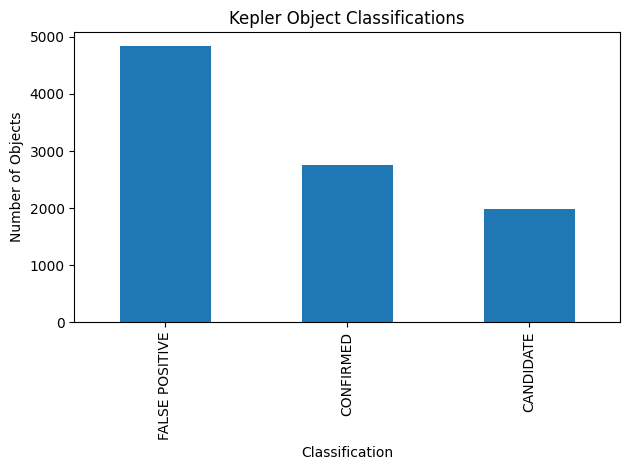

In [29]:
print(df["koi_disposition"].value_counts())

df["koi_disposition"].value_counts().plot(
    kind="bar",
    title="Kepler Object Classifications"
)

plt.xlabel("Classification")
plt.ylabel("Number of Objects")
plt.tight_layout()
plt.show()

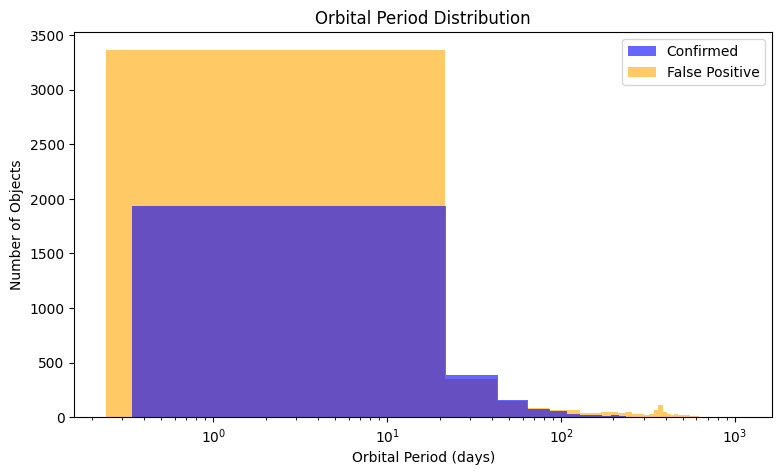

In [30]:
confirmed = df[
    df["koi_disposition"] == "CONFIRMED"
]

false_positive = df[
    df["koi_disposition"] == "FALSE POSITIVE"
]

plt.figure(figsize=(9, 5))

plt.hist(
    confirmed["koi_period"].dropna(),
    bins=50, alpha=0.6,
    label="Confirmed",
    color='blue',
    zorder=2
)

plt.hist(
    false_positive["koi_period"].dropna(),
    bins=50, alpha=0.6,
    label="False Positive",
    color='orange',
    zorder=1
)

plt.xscale("log")
plt.xlabel("Orbital Period (days)")
plt.ylabel("Number of Objects")
plt.legend()
plt.title("Orbital Period Distribution")
plt.show()

In [31]:
features = [
    "koi_period",
    "koi_duration",
    "koi_depth",
    "koi_impact",
    "koi_model_snr",
    "koi_steff",
    "koi_slogg",
    "koi_srad"
]

data = df[
    df["koi_disposition"].isin(
        ["CONFIRMED", "FALSE POSITIVE"]
    )
].copy()

data["target"] = (
    data["koi_disposition"] == "CONFIRMED"
).astype(int)

X = data[features]
y = data["target"]

print("Observations:", len(data))
print("Features:", len(features))

Observations: 7587
Features: 8


In [32]:
from sklearn.model_selection import GroupShuffleSplit

groups = data["kepid"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

model.fit(X_train, y_train)

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('histgradientboostingclassifier',
                 HistGradientBoostingClassifier(max_iter=200,
                                                random_state=42))])

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import pandas as pd
import matplotlib.pyplot as plt


In [34]:
models = {
    "Logistic Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    ),

    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42
        )
    ),

    "Gradient Boosting": make_pipeline(
        SimpleImputer(strategy="median"),
        HistGradientBoostingClassifier(
            max_iter=200,
            random_state=42
        )
    )
}


In [35]:
for name, model in models.items():

    print(f"Training {name}...")

    model.fit(X_train, y_train)

    print(f"{name} trained successfully!\n")

Training Logistic Regression...
Logistic Regression trained successfully!

Training Random Forest...
Random Forest trained successfully!

Training Gradient Boosting...
Gradient Boosting trained successfully!



In [36]:
results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.728,0.603,0.830,0.698,0.815
1,Random Forest,0.928,0.916,0.893,0.904,0.976
2,Gradient Boosting,0.933,0.910,0.915,0.912,0.978


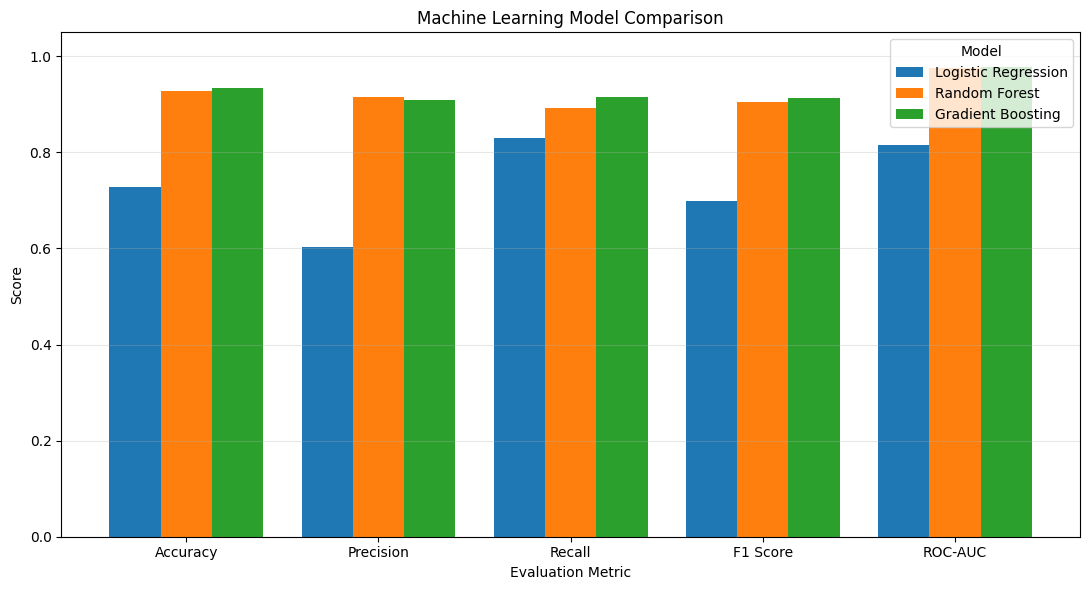

In [37]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

ax = results_df.set_index("Model")[metrics].T.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



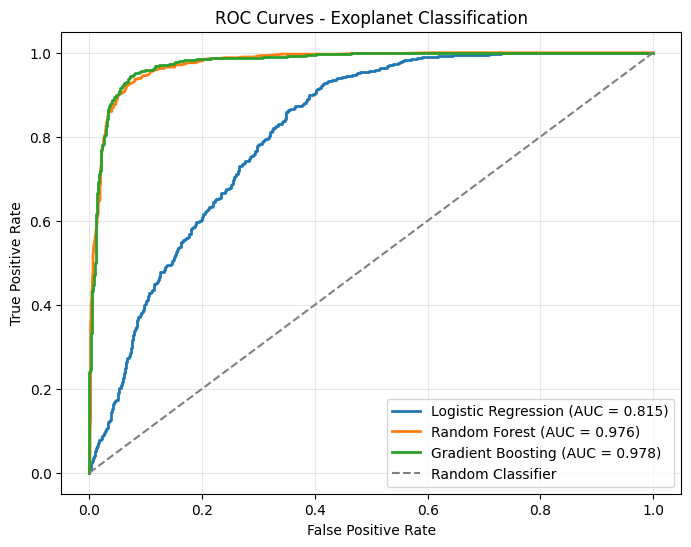

In [38]:
from sklearn.metrics import roc_curve
plt.figure(figsize=(8, 6))

for name, model in models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test, y_prob
    )

    auc = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="grey",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Exoplanet Classification")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


## **Model Comparison and Results**

### Objective

Three machine learning algorithms were trained and evaluated to classify Kepler observations as either confirmed exoplanets or false positives:


*   Logistic Regression
*   Random Forest
*   Gradient Boosting

All three models were evaluated using the same held-out test dataset, with observations grouped by host star to reduce data leakage.


### Model Performance Comparison

| Model | Accuracy | Precision | Recall | F1 Score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 0.728 | 0.603 | 0.830 | 0.698 | 0.815 |
| Random Forest | 0.928 | **0.916** | 0.893 | 0.904 | 0.976 |
| **Gradient Boosting** | **0.933** | 0.910 | **0.915** | **0.912** | **0.978** |

### Analysis of Results

**1. Best Performing Model**

Gradient Boosting achieved the highest overall accuracy (93.3%), F1 score (0.912) and ROC-AUC (0.978), making it the strongest overall performer in this comparison.

Random Forest performed similarly, achieving 92.8% accuracy and an F1 score of 0.904. It also achieved the highest precision (91.6%), meaning a slightly greater proportion of its predicted confirmed exoplanets were correctly classified.

**2. Precision and Recall**

Gradient Boosting achieved a recall of 91.5%, compared with 89.3% for Random Forest. This indicates that Gradient Boosting successfully identified a greater proportion of confirmed exoplanets in the test dataset.

However, Random Forest achieved slightly higher precision (91.6% versus 91.0%), suggesting it was marginally more reliable when predicting the confirmed class.

Logistic Regression achieved relatively high recall (83.0%) but much lower precision (60.3%), indicating that it incorrectly classified a larger proportion of false positives as confirmed exoplanets.

**3. Why did the models perform differently?**

Logistic Regression performed considerably worse than the two tree-based algorithms. One possible explanation is that the relationship between transit measurements and exoplanet classifications is nonlinear.

Random Forest and Gradient Boosting can capture complex interactions between features, such as orbital period, transit depth and signal-to-noise ratio, without requiring these relationships to be specified manually.

Gradient Boosting may have benefited from its sequential training approach, where successive trees improve upon the predictions of earlier trees.

###Conclusion

Gradient Boosting was the strongest overall algorithm in this experiment, achieving 93.3% accuracy and an F1 score of 0.912.

These results suggest that tree-based ensemble methods are more effective than the Logistic Regression baseline for classifying the selected Kepler observations.

However, the differences between Gradient Boosting and Random Forest are relatively small. Further testing using group-aware cross-validation and hyperparameter optimisation would be necessary to establish whether Gradient Boosting consistently performs better.

Additionally, the model predicts existing catalogue classifications rather than independently confirming the existence of exoplanets. Its performance should therefore be interpreted as classification agreement with the NASA dataset, not a direct measure of new planet discovery capability.



In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

physics_df = data.copy()

# Convert transit depth from ppm to a fraction
physics_df["transit_depth_fraction"] = (
    physics_df["koi_depth"] / 1_000_000
)

# Estimate planetary radius in Earth radii
physics_df["planet_radius_earth"] = (
    109.1
    * physics_df["koi_srad"]
    * np.sqrt(physics_df["transit_depth_fraction"])
)

# Remove invalid measurements
physics_df = physics_df[
    (physics_df["koi_depth"] > 0)
    & (physics_df["koi_srad"] > 0)
    & np.isfinite(physics_df["planet_radius_earth"])
].copy()

print(physics_df[
    [
        "kepoi_name",
        "koi_disposition",
        "koi_depth",
        "koi_srad",
        "planet_radius_earth"
    ]
].head(10).round(3))


   kepoi_name koi_disposition  koi_depth  koi_srad  planet_radius_earth
0   K00752.01       CONFIRMED      615.8     0.927                2.510
1   K00752.02       CONFIRMED      874.8     0.927                2.991
3   K00754.01  FALSE POSITIVE     8079.2     0.791                7.757
4   K00755.01       CONFIRMED      603.3     1.046                2.803
5   K00756.01       CONFIRMED     1517.5     0.972                4.131
6   K00756.02       CONFIRMED      686.0     0.972                2.777
7   K00756.03       CONFIRMED      226.5     0.972                1.596
8   K00114.01  FALSE POSITIVE      233.7     1.958                3.266
9   K00757.01       CONFIRMED     4914.3     0.848                6.486
10  K00001.01       CONFIRMED    14230.9     0.964               12.546


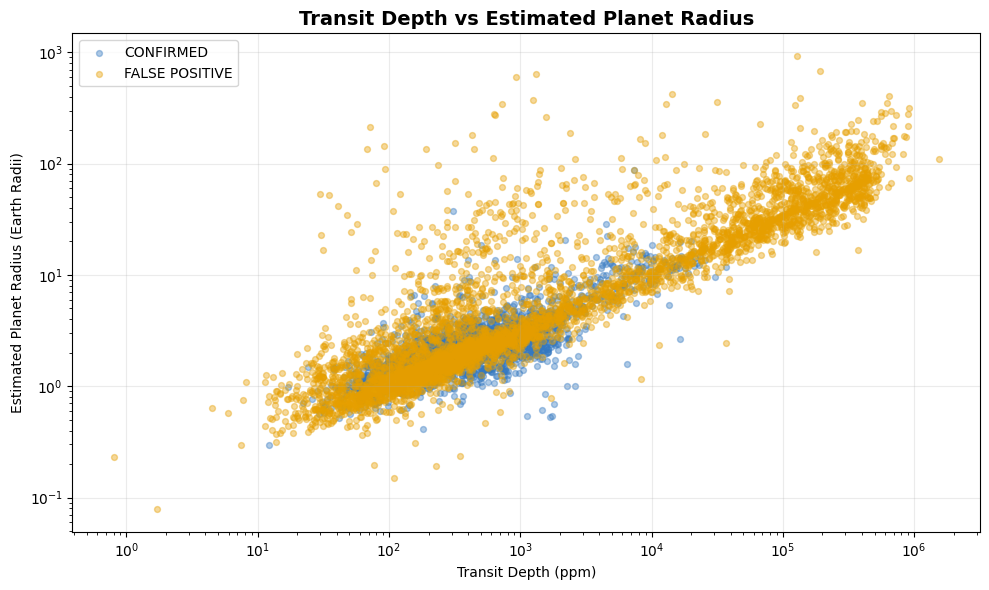

In [40]:
plt.figure(figsize=(10, 6))

colors = {
    "CONFIRMED": "#3478C0",
    "FALSE POSITIVE": "#E69F00"
}

for category, color in colors.items():

    subset = physics_df[
        physics_df["koi_disposition"] == category
    ]

    plt.scatter(
        subset["koi_depth"],
        subset["planet_radius_earth"],
        color=color,
        alpha=0.4,
        s=18,
        label=category
    )

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Transit Depth (ppm)")
plt.ylabel("Estimated Planet Radius (Earth Radii)")

plt.title(
    "Transit Depth vs Estimated Planet Radius",
    fontsize=14,
    fontweight="bold"
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


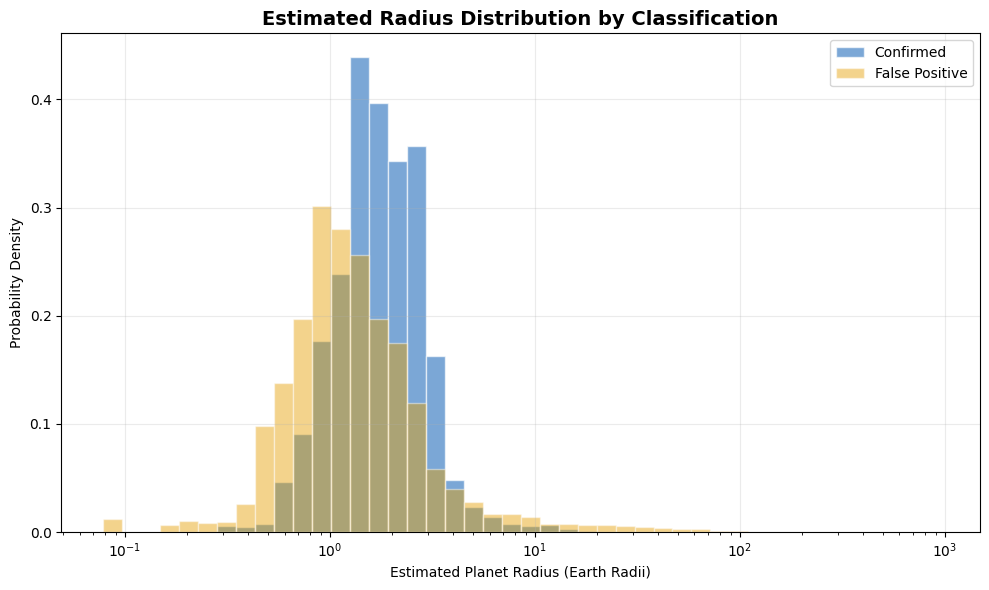

In [41]:
plt.figure(figsize=(10, 6))

confirmed = physics_df[
    physics_df["koi_disposition"] == "CONFIRMED"
]

false_positive = physics_df[
    physics_df["koi_disposition"] == "FALSE POSITIVE"
]

# Logarithmically spaced bins
all_radii = physics_df["planet_radius_earth"]

bins = np.logspace(
    np.log10(all_radii.min()),
    np.log10(all_radii.max()),
    45
)

plt.hist(
    confirmed["planet_radius_earth"],
    bins=bins,
    alpha=0.65,
    color="#3478C0",
    label="Confirmed",
    edgecolor="white",
    density=True
)

plt.hist(
    false_positive["planet_radius_earth"],
    bins=bins,
    alpha=0.45,
    color="#E69F00",
    label="False Positive",
    edgecolor="white",
    density=True
)

plt.xscale("log")

plt.xlabel("Estimated Planet Radius (Earth Radii)")
plt.ylabel("Probability Density")

plt.title(
    "Estimated Radius Distribution by Classification",
    fontsize=14,
    fontweight="bold"
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [42]:
# Copy the original ML dataset
X_extended = X.copy()

# Calculate the derived radius feature
X_extended["planet_radius_earth"] = (
    109.1
    * X_extended["koi_srad"]
    * np.sqrt(
        X_extended["koi_depth"].clip(lower=0)
        / 1_000_000
    )
)

# Reuse the same train/test indices from Step 7.1
X_train_extended = X_extended.iloc[train_idx]
X_test_extended = X_extended.iloc[test_idx]

print("Original features:", X.shape[1])
print("Extended features:", X_extended.shape[1])

Original features: 8
Extended features: 9


In [43]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score
)

extended_model = clone(models["Gradient Boosting"])

extended_model.fit(
    X_train_extended,
    y_train
)

extended_predictions = extended_model.predict(
    X_test_extended
)

extended_probabilities = extended_model.predict_proba(
    X_test_extended
)[:, 1]

print(
    "Accuracy:",
    round(
        accuracy_score(y_test, extended_predictions),
        3
    )
)

print(
    "F1 Score:",
    round(
        f1_score(y_test, extended_predictions),
        3
    )
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(y_test, extended_probabilities),
        3
    )
)

Accuracy: 0.935
F1 Score: 0.914
ROC-AUC: 0.979


## Physics-Based Feature Engineering Results
To investigate whether incorporating astrophysical knowledge could improve model performance, an additional feature representing estimated planetary radius was calculated using the transit depth equation:
$$R_p(R_\oplus) \approx 109.1 R_\star(R_\odot)\sqrt{\frac{\text{koi\_depth}}{10^6}}$$
The estimated planetary radius was added to the original eight features, and the Gradient Boosting model was retrained.
###Model Performance Comparison
| Metric | Original Model | Extended Model |
|---|---:|---:|
| Accuracy | 0.933 | **0.935** |
| F1 Score | 0.912 | **0.914** |
| ROC-AUC | 0.978 | **0.979** |
##Analysis

The extended model demonstrated a small improvement across all three evaluation metrics.

Accuracy increased from 93.3% to 93.5%, while the F1 score improved from 0.912 to 0.914. ROC-AUC also increased slightly, from 0.978 to 0.979.

These results suggest that incorporating a physically motivated feature may help the model identify relationships between stellar properties and transit measurements.

However, the estimated planetary radius is derived from two existing features, transit depth and stellar radius, meaning it does not introduce independent information.

Furthermore, the improvements are relatively small and were observed on a test dataset already used during model development. Additional group-aware cross-validation would be required to determine whether the improvement is consistent and generalises to unseen observations.

##Conclusion

This investigation demonstrates how domain-specific scientific knowledge can be incorporated into machine learning through feature engineering.

The extended Gradient Boosting model achieved the highest observed performance, with an accuracy of 93.5%, F1 score of 0.914 and ROC-AUC of 0.979.

The results provide preliminary evidence that physics-based feature engineering may improve classification performance, although further validation is necessary.



